In [32]:
import keras
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense,Dropout,Input
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [33]:
df=pd.read_csv("loan_approval_dataset.csv")
df.head(5)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [34]:
df.shape

(4269, 13)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [36]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4264    False
4265    False
4266    False
4267    False
4268    False
Length: 4269, dtype: bool

In [37]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [38]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


<Axes: xlabel=' cibil_score', ylabel='Density'>

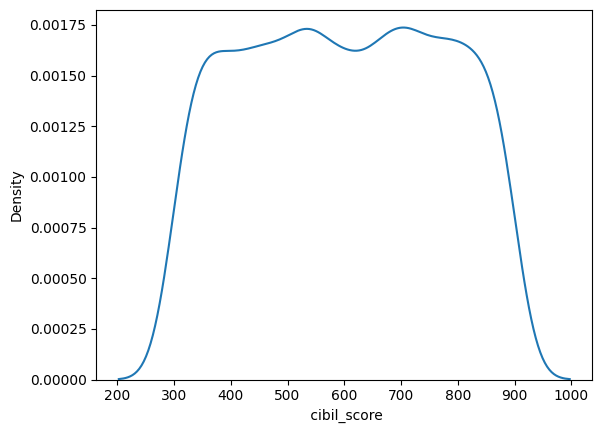

In [39]:
sns.kdeplot(df[' cibil_score'])

In [40]:
X=df.iloc[:,:-1]
y=df[' loan_status'].astype(str).str.strip()

In [41]:
# X.columns = X.columns.str.strip()

In [42]:
X.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value'],
      dtype='object')

In [43]:
cat_cols=X.select_dtypes(include=["object","category"]).columns.tolist()
num_cols=X.select_dtypes(include=["int64","float64"]).columns.tolist()

In [44]:
Processor=ColumnTransformer(transformers=[
    ("ST",StandardScaler(),num_cols),
    ("OHE",OneHotEncoder(drop='first',handle_unknown='ignore'),cat_cols)
])

In [45]:
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [46]:
X_train=Processor.fit_transform(X_train)
X_test=Processor.transform(X_test)

In [48]:
le = LabelEncoder()
Y_train = le.fit_transform(Y_train)
Y_test = le.transform(Y_test)

In [49]:
print("X_train:", X_train.shape, X_train.dtype)
print("Y_train:", Y_train.shape, Y_train.dtype)
print("X_test:", X_test.shape, X_test.dtype)
print("Y_test:", Y_test.shape, Y_test.dtype)

X_train: (3415, 12) float64
Y_train: (3415,) int64
X_test: (854, 12) float64
Y_test: (854,) int64


In [50]:
print(Y_train[:10])
print(Y_train.value_counts() if hasattr(Y_train, "value_counts") else "")
print(set(type(x) for x in Y_train))

[0 0 0 0 1 0 0 0 1 0]

{<class 'numpy.int64'>}


In [51]:
print(le.classes_)

[0 1]


In [52]:
model=Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16,activation='relu'),
    Dense(32,activation='relu'),
    Dense(64,activation='relu'),
    Dense(128,activation='relu'),
    Dense(1,activation='sigmoid')
    ])

In [53]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,313 (44.19 KB)

 Trainable params: 11,313 (44.19 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [55]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [56]:
history=model.fit(X_train,Y_train,epochs=10,validation_data=(X_test,Y_test),batch_size=32)

Epoch 1/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7666 - loss: 0.4571 - val_accuracy: 0.8829 - val_loss: 0.2646
Epoch 2/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8940 - loss: 0.2447 - val_accuracy: 0.9028 - val_loss: 0.2119
Epoch 3/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9130 - loss: 0.2018 - val_accuracy: 0.9110 - val_loss: 0.1949
Epoch 4/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9283 - loss: 0.1763 - val_accuracy: 0.9274 - val_loss: 0.1716
Epoch 5/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9347 - loss: 0.1548 - val_accuracy: 0.9286 - val_loss: 0.1639
Epoch 6/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9420 - loss: 0.1483 - val_accuracy: 0.9356 - val_loss: 0.1536
Epoch 7/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9449 - loss: 0.1353 - val_accuracy: 0.9426 - val_loss: 0.1355
Epoch 8/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9531 - loss: 0.1233 - val_accuracy: 

In [58]:
Y_pred=model.predict(X_test)

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


In [59]:
Y_pred=(Y_pred>0.5).astype(int)

In [61]:
from sklearn.metrics import accuracy_score

In [62]:
accuracy=accuracy_score(Y_test,Y_pred)*100

In [63]:
print(accuracy)

94.61358313817331


In [64]:
import joblib
joblib.dump(Processor,"preprocessor.pkl")

['preprocessor.pkl']

In [65]:
model.save("loan_approval_model.keras")